## Blue Jays 2025 postseason pitching: data cleaning and exploratory analysis

This notebook will build up the cleaned dataset that every analysis will start from.

It will also serve as a general exploration into our three questions:
1. **Speed and movement:** How Toronto's pitches compare by pitch type
2. **Clustering:** Where Toronto's pitching style fits regarding the 2025 postseason teams and pitchers
3. **Effectiveness:** What produces swings and misses (wiffs), and where the Jays are above or below expectation

#### Load and Review Data

- Confirm file contents
- Must be 2025 postseason year only
- Pitches must be unique
- Drop depreciated or uninformative variables
- Keep relevant variables only (Focusing on identification, location, and pitching)

In [1]:
# Libraries used
import numpy as np
import pandas as pd
from pathlib import Path

# Expand table view
pd.set_option('display.max_columns', 60)

# Folder to save tables/figures
OUT = Path('outputs/eda')
OUT.mkdir(parents = True, exist_ok = True)

In [2]:
# Read file
raw = pd.read_csv('MLB_Data.csv')

# Define a single pitch
pitch_key = ['game_pk', 'at_bat_number', 'pitch_number']

# Summary of contents
audit = pd.Series({
    'rows (pitches)': f"{len(raw):,}",
    'columns': raw.shape[1],
    'season(s)': ', '.join(map(str, sorted(raw['game_year'].unique()))),
    # F wild card, D division, L league championship, W World Series
    'game types': ', '.join(sorted(raw['game_type'].unique())),
    'first / last game date': f"{raw['game_date'].min()} / {raw['game_date'].max()}",
    'games': raw['game_pk'].nunique(),
    'pitchers': raw['pitcher'].nunique(),
    'duplicate pitch keys': int(raw.duplicated(pitch_key).sum()),
})
display(audit.to_frame('value'))

# Check for clear mistakes (Duplicates and wrong season)
assert raw['game_year'].eq(2025).all(), 'Not 2025 exclusive'
assert not raw.duplicated(pitch_key).any(), 'Duplicates found'

,value
rows (pitches),"14,096"
columns,95
season(s),2025
game types,"D, F, L, W"
first / last game date,2025-09-30 / 2025-11-01
games,47
pitchers,143
duplicate pitch keys,0


In [3]:
# Columns with no values at all carry no information (e.g. deprecated Statcast fields)
all_missing = [c for c in raw.columns if raw[c].isna().all()]
print(f"{len(all_missing)} columns are 100% empty: {', '.join(all_missing)}")

# Columns we keep: pitching-focused, so batter bat-tracking and fielding alignment are left out
keep_cols = [
    # who, where, when
    'game_pk', 'game_date', 'game_type', 'home_team', 'away_team', 'inning', 'inning_topbot',
    'at_bat_number', 'pitch_number', 'pitcher', 'player_name', 'batter', 'p_throws', 'stand',
    # game state (count, outs, runners on base, score)
    'balls', 'strikes', 'outs_when_up', 'on_1b', 'on_2b', 'on_3b',
    'home_score', 'away_score', 'bat_score', 'fld_score',
    'post_home_score', 'post_away_score', 'post_bat_score', 'post_fld_score',
    # pitch physics (speed, spin, release point, movement, trajectory)
    'pitch_type', 'pitch_name', 'release_speed', 'effective_speed', 'release_spin_rate', 'spin_axis',
    'release_extension', 'release_pos_x', 'release_pos_y', 'release_pos_z',
    'pfx_x', 'pfx_z', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az',
    # location and result of the pitch
    'zone', 'description', 'events', 'delta_run_exp',
    'woba_value', 'woba_denom', 'babip_value', 'iso_value',
    'estimated_ba_using_speedangle', 'estimated_woba_using_speedangle',
]

# Safety checks: every kept column exists, and none of them is an empty one
absent = [c for c in keep_cols if c not in raw.columns]
assert not absent, f"Not found in data: {absent}"
assert not set(keep_cols) & set(all_missing), 'A kept column is empty'

# Working copy used from here on
df = raw[keep_cols].copy()
print(f"Raw: {raw.shape}  ->  kept: {df.shape}")

8 columns are 100% empty: spin_dir, spin_rate_deprecated, break_angle_deprecated, break_length_deprecated, tfs_deprecated, tfs_zulu_deprecated, umpire, sv_id
Raw: (14096, 95)  ->  kept: (14096, 56)


#### Summary

**What we found.** The file holds 14,096 pitches in 95 columns from the 2025 postseason, with no duplicate pitches (both confirmed by the assertions above). Eight columns are completely empty (`spin_dir`, `umpire`, `sv_id` and five deprecated fields) and are dropped. We keep 56 columns describing the pitch, the game state and the result.

`pitching_team` is not in the raw file. We create it in Section 3 from the half-inning, because the home team pitches in the top half and the away team in the bottom half.

#### Simple Quality Checks
- Missing values
- Realistic value ranges (numerical values)
- Categories (label checks)

In [4]:
# Share of each kept column that is blank, in percent
miss_pct = df.isna().mean() * 100

# Most blanks are structural
reason = {}
for c in ['events', 'woba_value', 'woba_denom', 'babip_value', 'iso_value']:
    reason[c] = 'only filled on the pitch that ends the plate appearance'
for c in ['estimated_ba_using_speedangle', 'estimated_woba_using_speedangle']:
    reason[c] = 'only filled when the ball is put in play'
for c in ['on_1b', 'on_2b', 'on_3b']:
    reason[c] = 'blank = no runner on that base'

# Table of columns that have any blanks, with the reason for each (anything else is flagged as a real gap)
missing_table = (miss_pct[miss_pct > 0].round(3)
                 .to_frame('% missing')
                 .assign(reason = lambda t: [reason.get(c, 'unexplained (tracking gap)') for c in t.index])
                 .sort_values('% missing', ascending=False))
display(missing_table)

# For the real gaps, how many pitches are affected
for c in missing_table.index[missing_table['reason'].str.startswith('unexplained')]:
    print(f"{c}: {int(df[c].isna().sum())} affected pitches")

,% missing,reason
on_3b,91.019,blank = no runner on that base
estimated_ba_using_speedangle,83.087,only filled when the ball is put in play
on_2b,81.612,blank = no runner on that base
estimated_woba_using_speedangle,74.716,only filled when the ball is put in play
woba_denom,74.525,only filled on the pitch that ends the plate a...
iso_value,74.447,only filled on the pitch that ends the plate a...
woba_value,74.447,only filled on the pitch that ends the plate a...
babip_value,74.447,only filled on the pitch that ends the plate a...
events,74.447,only filled on the pitch that ends the plate a...
on_1b,67.998,blank = no runner on that base


release_spin_rate: 7 affected pitches
spin_axis: 7 affected pitches
effective_speed: 1 affected pitches


In [5]:
# Plausible limits for the numeric fields (speed in mph; movement and extension in feet)
plausible = {
    'release_speed':     (50, 106),
    'pfx_x':             (-3, 3),
    'pfx_z':             (-3, 3),
    'release_extension': (3, 9),
    'balls':             (0, 3),
    'strikes':           (0, 2),
    'outs_when_up':      (0, 2),
    # Statcast zones: 1-9 inside the strike zone, 11-14 outside
    'zone':              (1, 14),
    'inning':            (1, 20),
}

# Observed min and max, plus the number of non-blank values outside the plausible limits
range_check = pd.DataFrame({
    col: {'min': df[col].min(), 'max': df[col].max(),
          'outside plausible range': int((~df[col].between(lo, hi) & df[col].notna()).sum())}
    for col, (lo, hi) in plausible.items()
}).T
display(range_check)

,min,max,outside plausible range
release_speed,69.20,104.50,0.0
pfx_x,-2.03,1.85,0.0
pfx_z,-1.88,2.03,0.0
release_extension,5.10,8.20,0.0
balls,0.00,3.00,0.0
strikes,0.00,2.00,0.0
outs_when_up,0.00,2.00,0.0
zone,1.00,14.00,0.0
inning,1.00,18.00,0.0


In [6]:
# Categorical fields: only the expected labels should appear (and no blanks)
for col in ['stand', 'p_throws', 'inning_topbot', 'game_type', 'pitch_type']:
    print(col, df[col].value_counts(dropna = False).to_dict())

print("")

# Each pitcher ID should map to exactly one name (a mismatch would split one pitcher into two)
print('One name per pitcher id:', bool(df.groupby('pitcher')['player_name'].nunique().eq(1).all()))

stand {'R': 7581, 'L': 6515}
p_throws {'R': 10113, 'L': 3983}
inning_topbot {'Top': 7239, 'Bot': 6857}
game_type {'D': 5488, 'F': 3145, 'L': 3079, 'W': 2384}
pitch_type {'FF': 4649, 'SL': 2424, 'SI': 1988, 'CH': 1052, 'FS': 1047, 'CU': 1030, 'FC': 818, 'ST': 655, 'KC': 351, 'SV': 82}

One name per pitcher id: True


#### Summary

**Missing values.** Almost every blank is structural. Result fields (`events`, `woba_value`, `babip_value`, `iso_value`) are filled only on the pitch that ends a plate appearance, about 74% blank. The batted-ball estimates are blank unless the ball is put in play (74.7% and 83.1%). The runner columns are blank when the base is empty: 68.0% for first, 81.6% for second and 91.0% for third. These are not errors and are not imputed. The runner columns are converted to 0/1 flags in Section 3.

Only three columns have real tracking gaps: `effective_speed` (0.01%), `release_spin_rate` and `spin_axis` (0.05% each, about 7 pitches). We leave them blank in the master file. Analyses that need spin (clustering) drop those few pitches, and the effectiveness model doesn't use them.

**Ranges and categories.** The last column of the range table should be all zeros. Any non-zero count is investigated before we go on. Hand, half-inning and pitch-type fields should contain only the expected labels.

#### Shared Features

These columns are built once here so that all three analyses start from the same definitions. Nothing existing is overwritten; every step only adds columns, and `pitch_type` stays as recorded.

| New column | Meaning | Used by |
|---|---|---|
| `pitching_team`, `is_jays` | Team of the pitcher; 1 if Toronto | all |
| `base_state`, `base_state_label` | Runners on base (e.g. `101` = first and third) | effectiveness |
| `outing_id`, `outing_pitch_count`, `outing_total_pitches` | One pitcher in one game; running pitch count and outing length | speed, effectiveness |
| `pitcher_role` | Starter = first pitcher the team used in that game | speed, effectiveness |
| `horizontal_in`, `vertical_in` | Movement in inches; horizontal is mirrored so + = arm-side for both hands | speed and movement, clustering |
| `is_bunt`, `swing`, `whiff`, `pitch_result` | Outcome flags | effectiveness |

In [7]:
# The home team pitches in the Top half-inning and the away team pitches in the Bottom half
df['pitching_team'] = np.where(df['inning_topbot'] == 'Top', df['home_team'], df['away_team'])

# Indicator for Blue Jays pitchers (1 = Toronto pitching, 0 = any other team)
df['is_jays'] = (df['pitching_team'] == 'TOR').astype(int)

# Checks: the postseason teams, and every pitcher belongs to exactly one team
print(sorted(df['pitching_team'].unique()))
assert df.groupby('pitcher')['pitching_team'].nunique().eq(1).all(), 'A pitcher appears for two teams'

['BOS', 'CHC', 'CIN', 'CLE', 'DET', 'LAD', 'MIL', 'NYY', 'PHI', 'SD', 'SEA', 'TOR']


In [21]:
# Runner columns are filled with players ID when on base, and empty when not
# Convert to binary
for base in ['on_1b', 'on_2b', 'on_3b']:
    df[base] = df[base].notna().astype(int)

# One digit per base - '101' means on first and third
df['base_state'] = df['on_1b'].astype(str) + df['on_2b'].astype(str) + df['on_3b'].astype(str)

# Readable labels, in a fixed display order (an order for tables and plots, not a ranking)
base_labels = {'000': 'Empty', '100': '1st only', '010': '2nd only', '001': '3rd only',
               '110': '1st & 2nd', '101': '1st & 3rd', '011': '2nd & 3rd', '111': 'Loaded'}
df['base_state_label'] = df['base_state'].map(base_labels)

# Checks: no unexpected state, and the number of pitches in each state
assert df['base_state_label'].notna().all(), 'Unexpected base state value'
print(df['base_state'].value_counts().reindex(list(base_labels)))

base_state
000        NaN
100        NaN
010        NaN
001        NaN
110        NaN
101        NaN
011        NaN
111    14096.0
Name: count, dtype: float64


In [9]:
# Put pitches in the order they were thrown within each game
df = df.sort_values(pitch_key).reset_index(drop=True)

# One outing = one pitcher in one game. Running pitch count within the outing, and total outing length
df['outing_id'] = df['game_pk'].astype(str) + '_' + df['pitcher'].astype(str)
by_outing = df.groupby('outing_id')
# 1 for the first pitch, 2 for the second, ...
df['outing_pitch_count'] = by_outing.cumcount() + 1         
# pitches in the whole outing           
df['outing_total_pitches'] = by_outing['pitcher'].transform('size')

# Starter = the first pitcher each team used in each game; everyone else is a reliever
first_pitcher = df.groupby(['game_pk', 'pitching_team'])['pitcher'].transform('first')
df['pitcher_role'] = np.where(df['pitcher'] == first_pitcher, 'starter', 'reliever')

# Checks: exactly one starter per team per game, how many pitches each role threw, typical outing length
starters_per_game = (df[df['pitcher_role'] == 'starter']
                     .groupby(['game_pk', 'pitching_team'])['pitcher'].nunique())
print('Starters per team per game (expect all 1):', starters_per_game.value_counts().to_dict())
print(df['pitcher_role'].value_counts())
print(df.groupby('pitcher_role')['outing_total_pitches'].describe().round(1))

Starters per team per game (expect all 1): {1: 94}
pitcher_role
reliever    7234
starter     6862
Name: count, dtype: int64
               count  mean   std   min   25%   50%   75%    max
pitcher_role                                                   
reliever      7234.0  26.9  16.7   1.0  15.0  22.0  33.0   84.0
starter       6862.0  81.8  20.9  11.0  69.0  85.0  97.0  117.0


In [10]:
# Display names used in tables and plots
PT_NAMES = {'FF': 'Fastball', 'SI': 'Sinker', 'FC': 'Cutter', 'SL': 'Slider', 'ST': 'Sweeper',
            'CU': 'Curveball', 'KC': 'Knuckle curve', 'CH': 'Changeup', 'FS': 'Splitter', 'SV': 'Slurve'}
# the nine main types, fastballs first
pitch_order = ['FF', 'SI', 'FC', 'SL', 'ST', 'CU', 'KC', 'CH', 'FS']

# The slurve (SV) is rare. pitch_type is left as recorded; each analysis decides how to treat it
sv = df[df['pitch_type'] == 'SV']
print(f"Slurves: {len(sv)} pitches ({len(sv) / len(df):.1%} of all pitches)")
print('Thrown by:', sv['pitching_team'].value_counts().to_dict())

# Check: no pitch type other than the ones we have names for
assert set(df['pitch_type']) <= set(PT_NAMES), 'Unexpected pitch type'

Slurves: 82 pitches (0.6% of all pitches)
Thrown by: {'MIL': 37, 'CIN': 15, 'SEA': 13, 'CHC': 13, 'DET': 4}


In [11]:
# Movement is stored in feet from the catcher's view, so its sign flips with the pitcher's throwing hand.
# Convert to inches and mirror horizontal movement for right-handers so that + always means arm-side run
df['horizontal_in'] = 12 * df['pfx_x'] * df['p_throws'].map({'R': -1, 'L': 1})
# induced vertical movement; + = rises relative to a spin-free pitch
df['vertical_in'] = 12 * df['pfx_z']

# Check the mirroring: each pitch type should have the same sign for lefties (L) and righties (R)
display(df.pivot_table(index='pitch_type', columns='p_throws', values='horizontal_in', aggfunc='mean')
          .round(1).reindex(pitch_order + ['SV']))

p_throws,L,R
pitch_type,,
FF,6.7,7.4
SI,15.2,15.6
FC,-2.3,-2.9
SL,-3.7,-4.7
ST,-13.1,-13.7
CU,-10.1,-9.5
KC,-3.7,-6.6
CH,14.3,15.0
FS,11.8,11.2


In [12]:
# Groups of pitch descriptions
# bunt attempts (not a normal swing)
bunt_desc    = {'foul_bunt', 'missed_bunt', 'bunt_foul_tip'}
# swing and miss
whiff_desc   = {'swinging_strike', 'swinging_strike_blocked', 'foul_tip'}
# swing and contact
contact_desc = {'foul', 'hit_into_play'}

df['is_bunt'] = df['description'].isin(bunt_desc)
# a batter swing (bunts excluded)
df['swing'] = df['description'].isin(whiff_desc | contact_desc)
# 1 = swing and miss (meaningful only when swing is True)
df['whiff'] = df['description'].isin(whiff_desc).astype(int)

# One label per pitch for tables and plots: bunt / whiff / contact / no swing (a taken pitch)
df['pitch_result'] = np.select([df['is_bunt'], df['whiff'].eq(1), df['swing']],
                               ['bunt', 'whiff', 'contact'], default='no swing')

# Check: every description lands in the group we intend
display(pd.crosstab(df['description'], df['pitch_result']))

# The two working subsets used by the effectiveness analysis
non_bunt_pitches = df[~df['is_bunt']]
swings_only = non_bunt_pitches[non_bunt_pitches['swing']]
print(f"{df['is_bunt'].sum()} bunt rows | {len(non_bunt_pitches):,} non-bunt pitches | {len(swings_only):,} swings | "
      f"whiff per swing = {swings_only['whiff'].mean():.4f}")

pitch_result,bunt,contact,no swing,whiff
description,,,,
ball,0,0,4589,0
blocked_ball,0,0,338,0
bunt_foul_tip,1,0,0,0
called_strike,0,0,2249,0
foul,0,2539,0,0
foul_bunt,25,0,0,0
foul_tip,0,0,0,145
hit_by_pitch,0,0,45,0
hit_into_play,0,2395,0,0


33 bunt rows | 14,063 non-bunt pitches | 6,842 swings | whiff per swing = 0.2789


#### Summary

**Teams, runners and roles.** Twelve teams pitched in the postseason. Every pitcher belongs to one team and each team used exactly one starter in each of the 94 team-games. Starters threw 6,862 pitches and relievers 7,234. A typical starter outing is about 77 pitches and a typical reliever outing about 16, so pitch counts above 60 come almost entirely from starters. Most pitches (8,210) came with the bases empty, and the runner states with a runner on third only, or on second and third, are thin (233 and 238 pitches).

**Movement.** Horizontal movement is mirrored so that positive always means arm-side run. The L and R columns of the check table agree in sign for each pitch type, confirming the mirroring works.

**Slurves.** The slurve (`SV`) is rare. We leave it as recorded and each analysis states how it treats it: the effectiveness model folds it into curveballs and the speed-and-movement model excludes it.

**Outcomes.** 33 bunt attempts are set aside. That leaves 14,063 pitches, of which 6,842 are swings, and 27.9% of swings are whiffs.

#### Validate and Save Files

Before anything is saved, we confirm that this cleaned file reproduces the numbers from our original analysis, and that it matches the original cleaned file (`FullData_V1.csv`) on every column it had. Then we save the new master files. `pitch_type` is left exactly as recorded, so these files are safe for the speed/movement and clustering work as well.

In [13]:
# Check the master file against the numbers from our original analysis
jays = df[df['is_jays'] == 1]
# label order: Empty ... Loaded
base_counts = df['base_state'].value_counts().reindex(list(base_labels)).tolist() 
role_counts = df['pitcher_role'].value_counts()
# mean outing length, per pitch row
role_len = df.groupby('pitcher_role')['outing_total_pitches'].mean().round(1)
starters_per_game = (df[df['pitcher_role'] == 'starter']
                     .groupby(['game_pk', 'pitching_team'])['pitcher'].nunique().value_counts().to_dict())

# name: (expected from the original analysis, actual from this file)
expected = {
    'Pitches':                          (14096, len(df)),
    'Teams':                            (12, df['pitching_team'].nunique()),
    'Starters per team-game':           ({1: 94}, starters_per_game),
    'Starter pitches':                  (6862, int(role_counts.get('starter', 0))),
    'Reliever pitches':                 (7234, int(role_counts.get('reliever', 0))),
    'Mean outing length, starters':     (81.8, role_len.get('starter')),
    'Mean outing length, relievers':    (26.9, role_len.get('reliever')),
    'Base states (Empty ... Loaded)':   ([8210, 2699, 904, 233, 1017, 362, 238, 433], base_counts),
    'Jays pitches':                     (2788, len(jays)),
    'Jays games':                       (18, jays['game_pk'].nunique()),
    'Jays pitchers':                    (15, jays['pitcher'].nunique()),
    'Jays pitches by round':            ({'D': 597, 'L': 1029, 'W': 1162}, jays['game_type'].value_counts().to_dict()),
    'Bunt rows':                        (33, int(df['is_bunt'].sum())),
    'Non-bunt pitches':                 (14063, len(non_bunt_pitches)),
    'Swings':                           (6842, len(swings_only)),
    'Whiff per swing':                  (0.2789, round(swings_only['whiff'].mean(), 4)),
}

def same(a, b):
    # exact match for lists and dicts, tolerance for single numbers
    return a == b if isinstance(a, (list, dict)) else bool(np.isclose(a, b))

report = pd.DataFrame({k: {'expected': e, 'actual': a, 'match': same(e, a)} for k, (e, a) in expected.items()}).T
# transposing made this column object dtype
report['match'] = report['match'].astype(bool)                       
display(report)
assert report['match'].all(), f"Mismatch in: {list(report.index[~report['match']])}"
print('All known numbers reproduced.')

# For information: the effectiveness file should show the same counts (143 pitchers, 475 outings)
print(f"Swings come from {swings_only['pitcher'].nunique()} pitchers and {swings_only['outing_id'].nunique()} outings")

,expected,actual,match
Pitches,14096,14096,True
Teams,12,12,True
Starters per team-game,{1: 94},{1: 94},True
Starter pitches,6862,6862,True
Reliever pitches,7234,7234,True
"Mean outing length, starters",81.8,81.8,True
"Mean outing length, relievers",26.9,26.9,True
Base states (Empty ... Loaded),"[8210, 2699, 904, 233, 1017, 362, 238, 433]","[8210, 2699, 904, 233, 1017, 362, 238, 433]",True
Jays pitches,2788,2788,True
Jays games,18,18,True


All known numbers reproduced.
Swings come from 143 pitchers and 475 outings


In [14]:
# Reproduce the original cleaned file (FullData_V1.csv)
v1_path = Path('FullData_V1.csv')
if v1_path.exists():
    # base_state is text ('000', '110', ...)
    v1 = pd.read_csv(v1_path, dtype={'base_state': str})  
    # same pitch order as df         
    v1 = v1.sort_values(pitch_key).reset_index(drop=True)            
    assert len(v1) == len(df), 'Row counts differ'
    assert set(v1.columns) <= set(df.columns), f"Missing from new file: {set(v1.columns) - set(df.columns)}"
    differs = []
    for c in v1.columns:                                             # compare every original column
        try:
            pd.testing.assert_series_equal(df[c], v1[c], check_dtype=False, check_names=False)
        except AssertionError:
            differs.append(c)
    print(f"{len(v1.columns)} original columns compared; "
          f"{len(set(df.columns) - set(v1.columns))} columns are new in this file")
    assert not differs, f"Columns that differ from FullData_V1: {differs}"
    print('Identical to FullData_V1 on every original column.')
else:
    print('FullData_V1.csv not found here; skipping the comparison (the numbers above still check the file).')

62 original columns compared; 8 columns are new in this file
Identical to FullData_V1 on every original column.


In [15]:
# Save the master files
jays = df[df['is_jays'] == 1]
df.to_csv('FullData_V2.csv', index=False)
jays.to_csv('JaysData_V2.csv', index=False)

# Read both files back and confirm nothing changed in the round trip
for name, original in [('FullData_V2.csv', df), ('JaysData_V2.csv', jays)]:
    back = pd.read_csv(name, dtype={'base_state': str})              # keep base_state as text
    pd.testing.assert_frame_equal(back, original.reset_index(drop=True), check_dtype=False)
    print(f"{name}: {back.shape[0]:,} rows x {back.shape[1]} columns, read back identical")

FullData_V2.csv: 14,096 rows x 70 columns, read back identical
JaysData_V2.csv: 2,788 rows x 70 columns, read back identical


#### Summary

The cleaned file reproduces every number from our original analysis: 14,096 pitches, 12 teams, one starter per team per game, 2,788 Blue Jays pitches over 18 games, and 6,842 swings with a whiff rate of 27.9% once bunt attempts are set aside. It also matches `FullData_V1.csv` on all 62 original columns, so nothing downstream changes. Eight columns are new: `is_jays`, `outing_id`, the two movement features in inches, and the four pitch-outcome flags.

#### Conclusion

The general EDA and the effectiveness analysis use a cleaned master file (FullData_V2). The speed/movement and clustering analyses start from the same raw file (MLB_Data.csv, 14,096 pitches) and derive their own variables; we verified these match the master file. Three minor differences are documented: bunt attempts are excluded from swings in the effectiveness analysis but not in the clustering (33 pitches; league whiff rate 0.2789 vs 0.2785), the rare slurve (82 pitches, none thrown by the Jays) is merged, dropped or kept depending on the analysis, and starter is defined by first pitcher used in two analyses and by inning 1 in the clustering (3 non-Jays appearances).

#### General EDA

In [16]:
# Sample - how many pitches, games and pitchers, and where the Jays fit
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

def sample_row(d):
    # counts for one group of pitches: all stages from every pitch down to the swing sample
    nb = d[~d['is_bunt']]
    sw = nb[nb['swing']]
    return {'pitches': len(d), 'excluding bunt attempts': len(nb), 'swings': len(sw),
            'whiff per swing': round(sw['whiff'].mean(), 3),
            'games': d['game_pk'].nunique(), 'pitchers': d['pitcher'].nunique()}

# One column per group: all teams, then the Blue Jays
funnel = pd.DataFrame({'All teams': sample_row(df),
                       'Blue Jays': sample_row(df[df['is_jays'] == 1])})

# show counts as whole numbers and the whiff rate with 3 decimals (plain text, no extra package needed)
fmt = lambda x: f"{x:.3f}" if x < 1 else f"{x:,.0f}"
display(funnel.apply(lambda col: col.map(fmt)))

# Pitches and Jays share by playoff round
ROUND_NAMES = {'F': 'Wild Card', 'D': 'Division Series', 'L': 'League Championship', 'W': 'World Series'}
d_round = df.assign(round_name=df['game_type'].map(ROUND_NAMES))
by_round = d_round.groupby('round_name').agg(games=('game_pk', 'nunique'), pitches=('game_pk', 'size'),
                                             jays_pitches=('is_jays', 'sum'))
by_round['jays_games'] = d_round[d_round['is_jays'] == 1].groupby('round_name')['game_pk'].nunique()
by_round['jays_share'] = (by_round['jays_pitches'] / by_round['pitches']).round(3)
display(by_round.reindex([r for r in ROUND_NAMES.values() if r in by_round.index]).fillna(0).astype(
    {'jays_games': int}))

,All teams,Blue Jays
pitches,"14,096","2,788"
excluding bunt attempts,"14,063","2,784"
swings,"6,842","1,296"
whiff per swing,0.279,0.306
games,47,18
pitchers,143,15


,games,pitches,jays_pitches,jays_games,jays_share
round_name,,,,,
Wild Card,11,3145,0,0,0.000
Division Series,18,5488,597,4,0.109
League Championship,11,3079,1029,7,0.334
World Series,7,2384,1162,7,0.487


##### Q1 - Speed and Movement

In [17]:
# Palette shared by every figure: blue is always the Blue Jays
JAYS_BLUE, GREY, RED, DARK = '#2a78d6', '#9aa0a6', '#d6453d', '#5f6368'

Figure leaves out 82 slurve (SV) pitches; the master file is unchanged.


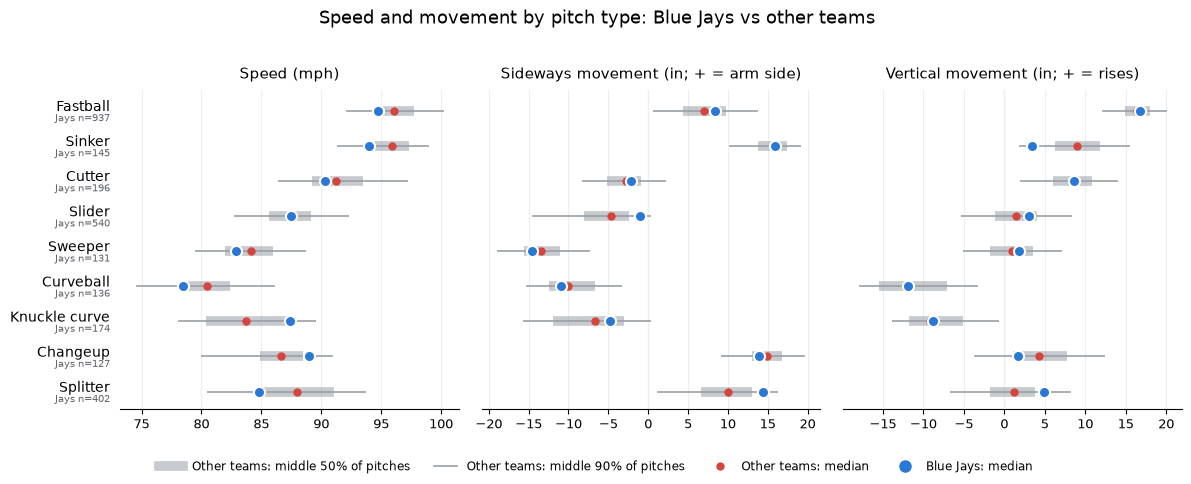

In [18]:
# A1 - speed and movement by pitch type: one figure, one panel per measure

# (column, panel title) for the three panels
measures = [('release_speed', 'Speed (mph)'),
            ('horizontal_in', 'Sideways movement (in; + = arm side)'),
            ('vertical_in',   'Vertical movement (in; + = rises)')]

# Display only: the rare slurve (SV) is left out of the figure
disp = df[df['pitch_type'].isin(pitch_order)]
print(f"Figure leaves out {int((df['pitch_type'] == 'SV').sum())} slurve (SV) pitches; the master file is unchanged.")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8), sharey=True)
for ax, (col, title) in zip(axes, measures):
    # One row per pitch type
    for i, pt in enumerate(pitch_order):
        # Values for other teams and for the Blue Jays
        league = disp.loc[(disp['pitch_type'] == pt) & (disp['is_jays'] == 0), col].dropna()
        jays_s = disp.loc[(disp['pitch_type'] == pt) & (disp['is_jays'] == 1), col].dropna()
        # The value that 5%, 25%, 50%, 75% and 95% of other teams' pitches fall below
        q05, q25, q50, q75, q95 = league.quantile([.05, .25, .5, .75, .95])
        # Thin line: where 90% of pitches fall; thick bar: the middle 50%
        ax.hlines(i, q05, q95, color=GREY, lw=1.2, zorder=1)
        ax.hlines(i, q25, q75, color=GREY, lw=7, alpha=.55, zorder=1)
        # Red dot: other teams' median; blue dot: Blue Jays' median
        ax.plot(q50, i, 'o', color=RED, ms=5, zorder=2)
        ax.plot(jays_s.median(), i, 'o', color=JAYS_BLUE, ms=8, mec='white', mew=1.5, zorder=3)
    # Zero line for the movement panels (no movement in that direction)
    if col != 'release_speed':
        ax.axvline(0, color='#d0d3d6', lw=.8, zorder=0)
    ax.set_title(title, fontsize=10.5, pad=8)
    ax.grid(axis='x', color='#eceef0', lw=.8)
    ax.set_axisbelow(True)
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    ax.set_yticks([])
    ax.tick_params(axis='x', labelsize=9)

# Row labels on the left panel only (pitch type, with the Jays pitch count)
for i, pt in enumerate(pitch_order):
    n_jays = int(((disp['pitch_type'] == pt) & (disp['is_jays'] == 1)).sum())
    axes[0].text(-0.03, i - 0.1, PT_NAMES[pt], transform=axes[0].get_yaxis_transform(), ha='right', va='center', fontsize=10)
    axes[0].text(-0.03, i + 0.22, f"Jays n={n_jays}", transform=axes[0].get_yaxis_transform(), ha='right', va='center',
                 fontsize=7.5, color=DARK)
# First pitch type at the top
axes[0].set_ylim(len(pitch_order) - 0.5, -0.6)

fig.suptitle('Speed and movement by pitch type: Blue Jays vs other teams', fontsize=13)
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
# Legend below the panels
fig.legend(handles=[plt.Line2D([], [], color=GREY, lw=7, alpha=.55, label='Other teams: middle 50% of pitches'),
                    plt.Line2D([], [], color=GREY, lw=1.2, label='Other teams: middle 90% of pitches'),
                    plt.Line2D([], [], marker='o', color=RED, lw=0, ms=5, label='Other teams: median'),
                    plt.Line2D([], [], marker='o', color=JAYS_BLUE, lw=0, ms=8, label='Blue Jays: median')],
           frameon=False, fontsize=8.5, loc='lower center', ncol=4)
fig.savefig(OUT / 'a1_speed_movement_by_pitch_type.png', dpi=200, bbox_inches='tight')
plt.show()

**What this figure shows.** Each row is one pitch type. For the other 11 teams we show where their pitches fall: the thin grey line covers the middle 90% of pitches, the thick grey bar the middle 50%, and the red dot is the median. The blue dot is the Blue Jays' median for the same pitch type, and "Jays n" is the number of Jays pitches behind it. Pitch types are compared separately because they differ so much in speed and movement. 

The Blue Jays' medians sit close to the field for most pitch types, with visible differences on a few. Each dot pools all pitches, so a few pitchers can drive a row.

##### Q2 - Clustering

13 of 15 Blue Jays pitchers shown; the rest threw fewer than 50 pitches.


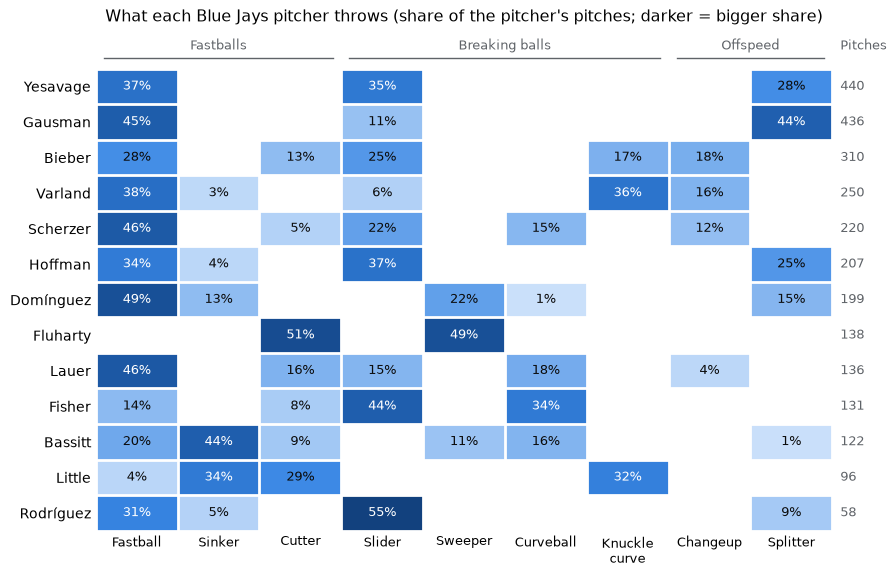

In [19]:
# A2 - pitch mix of each Blue Jays pitcher: share of their pitches by pitch type
from matplotlib.colors import LinearSegmentedColormap

# Pitchers with at least 50 pitches (the same minimum as the clustering work)
MIN_PITCHES = 50
jays_all = df[df['is_jays'] == 1]
n_pitches = jays_all['player_name'].value_counts()
keep = n_pitches[n_pitches >= MIN_PITCHES].index

# Share of each pitcher's pitches by type, columns in pitch_order (fastballs, breaking, offspeed)
mix = (pd.crosstab(jays_all['player_name'], jays_all['pitch_type'], normalize='index')
         .reindex(columns=pitch_order, fill_value=0).loc[keep])
# Pitcher with the most pitches at the top
mix = mix.loc[n_pitches[keep].sort_values(ascending=False).index]
print(f"{len(keep)} of {len(n_pitches)} Blue Jays pitchers shown; the rest threw fewer than {MIN_PITCHES} pitches.")

# Light-to-dark blue ramp: darker = a bigger share of that pitcher's pitches
BLUES = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
cmap = LinearSegmentedColormap.from_list('blues', BLUES)
VMAX = 0.60

fig, ax = plt.subplots(figsize=(9.5, 6))
# Pitch types a pitcher never threw are left blank
ax.imshow(np.ma.masked_where(mix.values == 0, mix.values), cmap=cmap, vmin=0, vmax=VMAX, aspect='auto')
for r in range(mix.shape[0]):
    for c in range(mix.shape[1]):
        v = mix.values[r, c]
        # Print the share in every filled cell; white text on the darker cells
        if v > 0:
            ax.text(c, r, f"{v:.0%}", ha='center', va='center', fontsize=9, color='white' if v >= .30 else '#0b0b0b')
# White gridlines between cells
ax.set_xticks(np.arange(-.5, mix.shape[1]), minor=True)
ax.set_yticks(np.arange(-.5, mix.shape[0]), minor=True)
ax.grid(which='minor', color='white', lw=2)
ax.tick_params(which='both', length=0)
for s in ax.spines.values():
    s.set_visible(False)

# Pitcher names on the left; number of pitches thrown in a column on the right
ax.set_yticks(range(mix.shape[0]), [name.split(',')[0] for name in mix.index], fontsize=10)
for r, name in enumerate(mix.index):
    ax.text(mix.shape[1] - .4, r, f"{n_pitches[name]}", ha='left', va='center', fontsize=9.5, color=DARK, clip_on=False)
ax.text(mix.shape[1] - .4, -.95, 'Pitches', ha='left', va='bottom', fontsize=9.5, color=DARK)
# Pitch type names under the columns (two lines for the long one)
ax.set_xticks(range(mix.shape[1]), [PT_NAMES[p].replace(' ', '\n') for p in mix.columns], fontsize=9)
# Pitch families above the columns
for x0, x1, label in [(-.5, 2.5, 'Fastballs'), (2.5, 6.5, 'Breaking balls'), (6.5, 8.5, 'Offspeed')]:
    ax.plot([x0 + .1, x1 - .1], [-.8, -.8], color=DARK, lw=1, clip_on=False)
    ax.text((x0 + x1) / 2, -.95, label, ha='center', va='bottom', fontsize=9.5, color=DARK)
ax.set_ylim(mix.shape[0] - .5, -.5)
ax.set_title("What each Blue Jays pitcher throws (share of the pitcher's pitches; darker = bigger share)", fontsize=11.5, pad=34)
fig.savefig(OUT / 'a2_jays_pitch_mix.png', dpi=200, bbox_inches='tight')
plt.show()

**What this figure shows.** Each row is one Blue Jays pitcher with at least 50 pitches, ordered by how many pitches they threw (the count is on the right). Each column is a pitch type, and each cell shows the share of that pitcher's pitches; darker means a bigger share and blank means the pitcher never threw it. The Blue Jays do not share one recipe: Fluharty throws cutters and sweepers almost exclusively, Gausman splits his pitches between fastballs and splitters, and Rodríguez throws sliders more than half the time. This tells us what each pitcher throws, not their overall style, which is the question the clustering takes on.

##### Q3 - Effectiveness

Figure leaves out 29 slurve (SV) swings; the master file is unchanged.


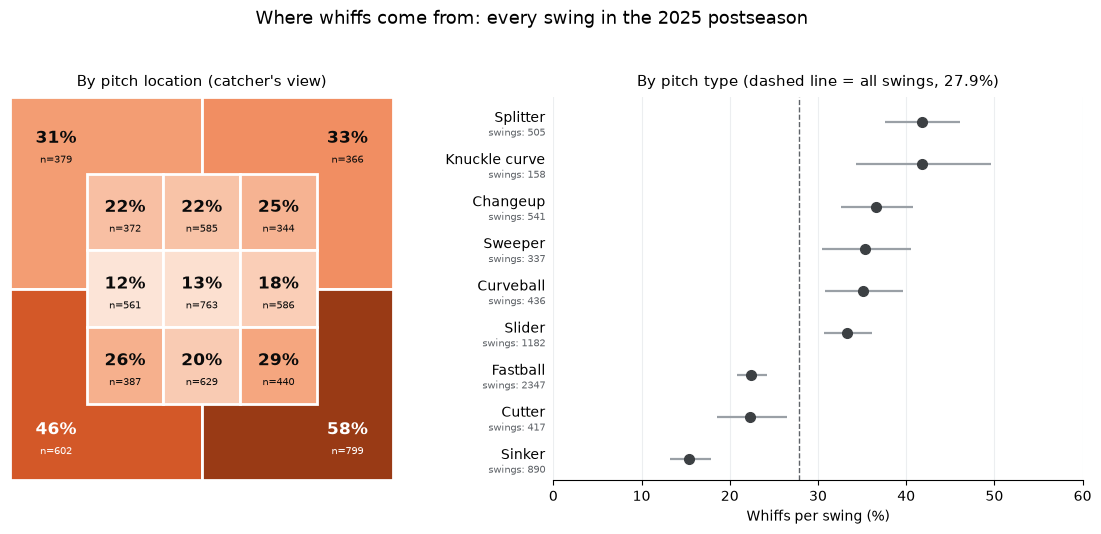

In [20]:
# A3 - where whiffs come from: all postseason swings, by pitch location and by pitch type
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

# Swings only (bunt attempts are not counted as swings); the rare slurve (SV) is left out of the figure
swings_all = disp[(~disp['is_bunt']) & disp['swing']]
overall = swings_all['whiff'].mean()
print(f"Figure leaves out {int(((df['pitch_type'] == 'SV') & (~df['is_bunt']) & df['swing']).sum())} slurve (SV) swings; the master file is unchanged.")

def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion k out of n
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

# Light-to-dark orange ramp for the location panel (blue is kept for the Blue Jays in the other figures)
ORANGES = ['#fdeadf', '#f9c9b0', '#f4a077', '#eb6834', '#c24d1f', '#8f3512']
cmap = LinearSegmentedColormap.from_list('oranges', ORANGES)
VMIN, VMAX = 0.10, 0.60

fig, (axz, axp) = plt.subplots(1, 2, figsize=(11.5, 5.4), gridspec_kw={'width_ratios': [1, 1.15]})

# ---- Left: strike-zone grid, as seen from the catcher (zones 1-9 inside, 11-14 outside corners)
by_zone = swings_all.groupby('zone')['whiff'].agg(['mean', 'size'])
def zone_color(z):
    return cmap((by_zone.loc[z, 'mean'] - VMIN) / (VMAX - VMIN))
def zone_label(ax, x, y, z):
    m, n = by_zone.loc[z, 'mean'], int(by_zone.loc[z, 'size'])
    # White text on the darker cells
    col = 'white' if m >= .40 else '#0b0b0b'
    ax.text(x, y + .06, f"{m:.0%}", ha='center', va='center', fontsize=12, color=col, fontweight='bold')
    ax.text(x, y - .22, f"n={n}", ha='center', va='center', fontsize=7.5, color=col)
# Outside corners first (big rectangles behind), then the nine inner cells on top
for z, (x0, y0) in {11: (0, 2.5), 12: (2.5, 2.5), 13: (0, 0), 14: (2.5, 0)}.items():
    axz.add_patch(Rectangle((x0, y0), 2.5, 2.5, facecolor=zone_color(z), edgecolor='white', lw=2))
inner = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]
for i, row in enumerate(inner):
    for j, z in enumerate(row):
        x0, y0 = 1 + j, 3 - i
        axz.add_patch(Rectangle((x0, y0), 1, 1, facecolor=zone_color(z), edgecolor='white', lw=2))
        zone_label(axz, x0 + .5, y0 + .5, z)
for z, (x, y) in {11: (.6, 4.4), 12: (4.4, 4.4), 13: (.6, .6), 14: (4.4, .6)}.items():
    zone_label(axz, x, y, z)
axz.set_xlim(0, 5)
axz.set_ylim(0, 5)
axz.set_aspect('equal')
axz.axis('off')
axz.set_title("By pitch location (catcher's view)", fontsize=11, pad=8)

# ---- Right: whiff per swing by pitch type, from the highest to the lowest
rows = []
for pt in pitch_order:
    g = swings_all[swings_all['pitch_type'] == pt]
    k, n = int(g['whiff'].sum()), len(g)
    lo, hi = wilson(k, n)
    rows.append({'pt': pt, 'rate': k / n, 'lo': lo, 'hi': hi, 'n': n})
bt = pd.DataFrame(rows).sort_values('rate', ascending=False).reset_index(drop=True)
# Dashed line: whiff per swing over all swings shown
axp.axvline(100 * overall, color=DARK, ls='--', lw=1, zorder=0)
for i, r in bt.iterrows():
    axp.hlines(i, 100 * r['lo'], 100 * r['hi'], color=GREY, lw=1.6, zorder=1)
    axp.plot(100 * r['rate'], i, 'o', color='#3c4043', ms=7, zorder=2)
    axp.text(-0.015, i - 0.1, PT_NAMES[r['pt']], transform=axp.get_yaxis_transform(), ha='right', va='center', fontsize=10)
    axp.text(-0.015, i + 0.25, f"swings: {int(r['n'])}", transform=axp.get_yaxis_transform(), ha='right', va='center', fontsize=7.5, color=DARK)
axp.set_yticks([])
axp.set_ylim(len(bt) - 0.5, -0.6)
axp.set_xlim(0, 60)
axp.set_xlabel('Whiffs per swing (%)', fontsize=10)
axp.grid(axis='x', color='#eceef0', lw=.8)
axp.set_axisbelow(True)
for s in ['top', 'right', 'left']:
    axp.spines[s].set_visible(False)
axp.set_title(f"By pitch type (dashed line = all swings, {overall:.1%})", fontsize=11, pad=8)

fig.suptitle('Where whiffs come from: every swing in the 2025 postseason', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(OUT / 'a3_whiff_location_type.png', dpi=200, bbox_inches='tight')
plt.show()

**What this figure shows.** Every swing in the 2025 postseason, all teams together. The left panel is the strike zone as seen from the catcher: the nine inner squares are the strike zone, the four large corners are pitches just outside it, and each square shows the share of swings that were whiffs (a swing and a miss, including foul tips) and the number of swings. Whiffs are rare over the middle of the plate (about 12-13%) and common low and outside (46-58%). The right panel gives the same measure by pitch type, with a 95% interval; the dashed line is the rate across all swings. Splitters and knuckle curves miss most often and sinkers least, but those pitch types are also thrown to different locations, so this panel alone does not separate pitch type from where the pitch goes. The intervals treat every swing as independent, so they are too narrow.